# 02 Analysis

Every table and figure in the manuscript comes from this notebook. It reads only the de-identified files written by `01_prepare_data.ipynb` and saves results to `results/`.

The quantitative analysis is descriptive. No inferential tests are run, because a single-arm design cannot support causal inference and the sample is too small to estimate effects with useful precision.

In [1]:
import json
import textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "results" / "figures"
TABLES = ROOT / "results" / "tables"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.linewidth": 0.8})

## Data

In [2]:
surveys = {name: pd.read_csv(PROCESSED / f"{name}.csv")
           for name in ["child_first", "child_second", "adult_first", "adult_second"]}
board = pd.read_csv(PROCESSED / "advisory_board.csv")
qualitative = pd.read_csv(PROCESSED / "qualitative_counts.csv")
summary = json.loads((PROCESSED / "cohort_summary.json").read_text())

child_first, child_second = surveys["child_first"], surveys["child_second"]
adult_first, adult_second = surveys["adult_first"], surveys["adult_second"]

for name, df in surveys.items():
    print(f"{name:13} {len(df):3} surveys")

child_first    20 surveys
child_second   10 surveys
adult_first    83 surveys
adult_second   39 surveys


## Survey items

All nine items say that GAME has already helped, for example "Participating in the GAME classes has improved my sleep." Because of that wording the two surveys are treated as a first and a second administration rather than a baseline and a follow-up.

Agreement means "strongly agree" or "somewhat agree". The child form was completed by a parent and each item referred to the child.

In [3]:
ITEMS = {
    1: "Improved my sleep",
    2: "Improved my mood",
    3: "Brought me joy",
    4: "Helped me manage stress",
    5: "Helped reduce existing pain",
    6: "Increased my ability to connect with others",
    7: "Increased my daily movements",
    8: "Helped me lose weight",
    9: "Reduced my loneliness",
}
CHILD_ITEMS = {
    1: "Improved my child's sleep",
    2: "Improved my child's mood",
    3: "Brought my child joy",
    4: "Helped my child manage stress",
    5: "Helped reduce my child's existing pain",
    6: "Increased my child's ability to connect with others",
    7: "Increased my child's daily movements",
    8: "Helped my child lose weight",
    9: "Reduced my child's loneliness",
}
AGREE = ["Strongly agree", "Somewhat agree"]
DISAGREE = ["Somewhat disagree", "Strongly disagree"]
OPTIONS = ["Strongly agree", "Somewhat agree", "Neutral", "Somewhat disagree",
           "Strongly disagree", "Not applicable", "No response"]


def option(value):
    # the child form says "not applicable to my child" and the adult form "to me"
    if pd.isna(value):
        return "No response"
    return "Not applicable" if str(value).startswith("Not applicable") else str(value)

## Who returned a second survey

Every second survey belongs to someone who returned a first survey. Most link to a first survey on the same form; two came from children who did the child survey first and answered the adolescent and adult survey the second time.

In [4]:
first_ids = set(child_first["study_id"]) | set(adult_first["study_id"])
second_ids = set(child_second["study_id"]) | set(adult_second["study_id"])
assert second_ids <= first_ids
assert len(second_ids) == len(child_second) + len(adult_second)

n_unique = summary["unique_participants"]
n_returned = len(second_ids)
flow = pd.Series({
    "unique participants who returned a first survey": n_unique,
    "first surveys, child form": len(child_first),
    "first surveys, adolescent and adult form": len(adult_first),
    "people who returned a second survey": n_returned,
    "second surveys, child form": len(child_second),
    "second surveys, adolescent and adult form": len(adult_second),
    "linked on the same form, child": int(child_second["linked_same_form"].sum()),
    "linked on the same form, adolescent and adult": int(adult_second["linked_same_form"].sum()),
    "linked after resolving a name variant": int((adult_second["link_method"] == "name variant").sum()),
    "adolescent and adult second surveys from children": int(adult_second["first_survey_on_child_form"].sum()),
})
print(flow.to_string())
print(f"\nreturned a second survey: {n_returned} of {n_unique} ({n_returned / n_unique * 100:.1f}%)")

unique participants who returned a first survey      101
first surveys, child form                             20
first surveys, adolescent and adult form              83
people who returned a second survey                   49
second surveys, child form                            10
second surveys, adolescent and adult form             39
linked on the same form, child                        10
linked on the same form, adolescent and adult         37
linked after resolving a name variant                  4
adolescent and adult second surveys from children      2

returned a second survey: 49 of 101 (48.5%)


## Sites and families

Site was a check-all question, so people who attended more than one site are counted under the first site they listed.

In [5]:
def first_site(value):
    return str(value).split(",")[0].strip()

for name in ["child_first", "adult_first"]:
    sites = surveys[name]["site"]
    print(f"{name}: {sites.map(first_site).value_counts().to_dict()}")
    print(f"   listed more than one site: {int(sites.astype(str).str.contains(',').sum())}, "
          f"listed Northside Elementary at all: {int(sites.astype(str).str.contains('Northside').sum())}")

print(f"\nparents or guardians behind the child surveys: {summary['parents_or_guardians']}")
print(f"parents who enrolled two children: {summary['parents_with_two_children']}")
print(f"parents who also completed an adult survey (identical name, so a floor): "
      f"{summary['parents_also_adult_survey_identical_name']}")
print(f"advisory board members who also completed participant surveys: "
      f"{summary['advisory_board_in_participant_surveys']} of {summary['advisory_board_members']}")

child_first: {'Eagle Heights Community Center': 10, 'Northside Elementary School': 7, 'Life Center Madison': 3}
   listed more than one site: 0, listed Northside Elementary at all: 7
adult_first: {'Eagle Heights Community Center': 76, 'Life Center Madison': 7}
   listed more than one site: 5, listed Northside Elementary at all: 3

parents or guardians behind the child surveys: 17
parents who enrolled two children: 3
parents who also completed an adult survey (identical name, so a floor): 5
advisory board members who also completed participant surveys: 7 of 11


## Table 1

Participant characteristics by survey. Percentages are column percentages and include people who left the question blank. Race and ethnicity allowed more than one answer, and someone who chose several is shown under the first one.

In [6]:
INCOME_ORDER = ["Under $25,000", "$25,000 to just under $50,000", "$50,000 to just under $75,000",
                "$75,000 to just under $100,000", "$100,000 to just under $150,000",
                "$150,000 or more", "No response"]
RACE_ORDER = ["Black/African American", "Asian", "Hispanic/Latino", "White/Caucasian",
              "Middle Eastern/North African", "Native American/Alaskan Native",
              "Not listed (please specify):", "No response"]
GENDER_ORDER = ["Male", "Female", "No response"]
AGE_ORDER = ["5 years", "6 to 12 years", "13 to 17 years", "18 to 29 years", "30 to 39 years",
             "40 to 49 years", "50 to 59 years", "60 years and older", "No response"]
LABELS = {"child_first": "Child survey, first", "child_second": "Child survey, second",
          "adult_first": "Adolescent and adult survey, first",
          "adult_second": "Adolescent and adult survey, second"}


def column_percent(values, order):
    values = values.fillna("No response")
    unexpected = set(values) - set(order)
    assert not unexpected, f"categories missing from the table: {unexpected}"
    return values.value_counts(normalize=True).mul(100).reindex(order, fill_value=0).round(1)


blocks = {"Household income, %": ("income", INCOME_ORDER),
          "Race and ethnicity, %": ("race", RACE_ORDER),
          "Gender, %": ("gender", GENDER_ORDER),
          "Age, %": ("age_band", AGE_ORDER)}
table1 = pd.concat({
    title: pd.DataFrame({f"{LABELS[k]} (n={len(df)})": column_percent(df[col], order)
                         for k, df in surveys.items()})
    for title, (col, order) in blocks.items()
})

sums = table1.groupby(level=0).sum()
assert ((sums - 100).abs() < 0.35).all().all()
multi = int(child_first["race_more_than_one"].sum() + adult_first["race_more_than_one"].sum())
print(f"first-survey respondents who chose more than one race or ethnicity: {multi}")
table1

first-survey respondents who chose more than one race or ethnicity: 5


Child survey, first (n=20)  Child survey, second (n=10)  Adolescent and adult survey, first (n=83)  \
Household income, %   Under $25,000                                           0.0                          0.0                                       26.5   
                      $25,000 to just under $50,000                          30.0                         30.0                                       20.5   
                      $50,000 to just under $75,000                           5.0                         10.0                                       14.5   
                      $75,000 to just under $100,000                         20.0                         40.0                                        7.2   
                      $100,000 to just under $150,000                        20.0                         10.0                                        8.4   
                      $150,000 or more                                        5.0                          0.0                                        7.2   
                      No response                                            20.0                         10.0                                       15.7   
Race and ethnicity, % Black/African American                                 45.0                         40.0                                       28.9   
                      Asian                                                   5.0                          0.0                                       24.1   
                      Hispanic/Latino                                        10.0                         20.0                                       12.0   
                      White/Caucasian                                        25.0                         40.0                                       21.7   
                      Middle Eastern/North African                            0.0                          0.0                                        1.2   
                      Native American/Alaskan Native                          0.0                          0.0                                        0.0   
                      Not listed (please specify):                            0.0                          0.0                                        2.4   
                      No response                                            15.0                          0.0                                        9.6   
Gender, %             Male                                                   45.0                         50.0                                       19.3   
                      Female                                                 40.0                         50.0                                       71.1   
                      No response                                            15.0                          0.0                                        9.6   
Age, %                5 years                                                25.0                         20.0                                        0.0   
                      6 to 12 years                                          55.0                         70.0                                        0.0   
                      13 to 17 years                                          5.0                         10.0                                        1.2   
                      18 to 29 years                                          0.0                          0.0                                       16.9   
                      30 to 39 years                                          0.0                          0.0                                       45.8   
                      40 to 49 years                                          0.0                          0.0                                       12.0   
                      50 to 59 years                                          0.0                          0.0                    

## Supplemental Table 1: advisory board

In [7]:
supp1 = pd.concat({
    title: column_percent(board[col], order).rename(f"Advisory board (n={len(board)})").to_frame()
    for title, (col, order) in blocks.items()
})
supp1

Advisory board (n=11)
Household income, %   Under $25,000                                     36.4
                      $25,000 to just under $50,000                      9.1
                      $50,000 to just under $75,000                     27.3
                      $75,000 to just under $100,000                     9.1
                      $100,000 to just under $150,000                    9.1
                      $150,000 or more                                   0.0
                      No response                                        9.1
Race and ethnicity, % Black/African American                            54.5
                      Asian                                              0.0
                      Hispanic/Latino                                    0.0
                      White/Caucasian                                   36.4
                      Middle Eastern/North African                       0.0
                      Native American/Alaskan Native                     0.0
                      Not listed (please specify):                       9.1
                      No response                                        0.0
Gender, %             Male                                              54.5
                      Female                                            45.5
                      No response                                        0.0
Age, %                5 years                                            0.0
                      6 to 12 years                                      0.0
                      13 to 17 years                                     0.0
                      18 to 29 years                                    36.4
                      30 to 39 years                                    27.3
                      40 to 49 years                                    27.3
                      50 to 59 years                                     0.0
                      60 years and older                                 9.1
                      No response                                        0.0

## Time between the two surveys

The program ran on a rolling basis, so the gap between someone's first and second survey varies a lot. This is part of why the first survey cannot be read as a baseline.

In [8]:
def interval_summary(second):
    days = second.loc[second["linked_same_form"], "days_since_first"]
    usable = days[days >= 0]
    return pd.Series({
        "linked pairs": len(days),
        "second survey dated before the first": int((days < 0).sum()),
        "shortest (days)": int(usable.min()),
        "median (days)": float(usable.median()),
        "longest (days)": int(usable.max()),
        "same day": int((usable == 0).sum()),
        "under 8 weeks, including same day": int((usable < 56).sum()),
    }, dtype=object)


intervals = pd.DataFrame({"Child survey": interval_summary(child_second),
                          "Adolescent and adult survey": interval_summary(adult_second)})
intervals

,Child survey,Adolescent and adult survey
linked pairs,10,37
second survey dated before the first,0,1
shortest (days),0,11
median (days),55.0,45.0
longest (days),141,177
same day,2,0
"under 8 weeks, including same day",5,24


## Paired results

A pair is one person's first and second survey on the same form. Pairs where the second survey is dated before the first are dropped. For each item a pair counts only if the person answered that item both times, so a skipped question is never read as disagreement. "Not applicable" is an answer and stays in.

In [9]:
def pairs_for(first, second, drop_ids=()):
    keep = (second["linked_same_form"]
            & (second["days_since_first"] >= 0)
            & ~second["study_id"].isin(list(drop_ids)))
    return second[keep].merge(first, on="study_id", suffixes=("_second", "_first"))


def paired_table(first, second, labels, drop_ids=()):
    pairs = pairs_for(first, second, drop_ids)
    rows = []
    for k, label in labels.items():
        before, after = pairs[f"item_{k}_first"], pairs[f"item_{k}_second"]
        both = before.notna() & after.notna()
        before, after = before[both], after[both]
        rows.append({
            "item": label,
            "n": int(both.sum()),
            "agree_first": int(before.isin(AGREE).sum()),
            "agree_second": int(after.isin(AGREE).sum()),
            "disagree_first": int(before.isin(DISAGREE).sum()),
            "disagree_second": int(after.isin(DISAGREE).sum()),
        })
    table = pd.DataFrame(rows).set_index("item")
    table["change"] = table["agree_second"] - table["agree_first"]
    table["agree_first_pct"] = (table["agree_first"] / table["n"] * 100).round(1)
    table["agree_second_pct"] = (table["agree_second"] / table["n"] * 100).round(1)

    first_cols = [f"item_{k}_first" for k in labels]
    second_cols = [f"item_{k}_second" for k in labels]
    answered = pairs[first_cols].notna().to_numpy() & pairs[second_cols].notna().to_numpy()
    return table, int(answered.any(axis=1).sum()), pairs


adults, n_adult_pairs, adult_pairs = paired_table(adult_first, adult_second, ITEMS)
children, n_child_pairs, child_pairs = paired_table(child_first, child_second, CHILD_ITEMS)

n_before_first = int((adult_second["linked_same_form"] & (adult_second["days_since_first"] < 0)).sum())
n_no_answers = len(adult_pairs) - n_adult_pairs
print(f"adult pairs: {n_adult_pairs} "
      f"(dropped: {n_before_first} with the second survey dated first, "
      f"{n_no_answers} with no item answered on the first survey)")
print(f"child pairs: {n_child_pairs}")
print(f"item denominators, adults: {sorted(set(adults['n'].tolist()))}, children: {sorted(set(children['n'].tolist()))}")

answered_first = adult_pairs[[f"item_{k}_first" for k in ITEMS]].notna().any(axis=1)
adult_ages = adult_pairs.loc[answered_first, "age_band_second"]
assert not adult_ages.isin(["5 years", "6 to 12 years", "13 to 17 years", "No response"]).any()
print("every paired adolescent and adult respondent was 18 or older at the second survey")
adults

adult pairs: 34 (dropped: 1 with the second survey dated first, 2 with no item answered on the first survey)
child pairs: 10
item denominators, adults: [33, 34], children: [10]
every paired adolescent and adult respondent was 18 or older at the second survey


,n,agree_first,agree_second,disagree_first,disagree_second,change,agree_first_pct,agree_second_pct
item,,,,,,,,
Improved my sleep,34,23,24,3,4,1,67.6,70.6
Improved my mood,33,29,29,3,2,0,87.9,87.9
Brought me joy,34,30,29,3,3,-1,88.2,85.3
Helped me manage stress,33,22,25,4,3,3,66.7,75.8
Helped reduce existing pain,34,18,17,5,3,-1,52.9,50.0
Increased my ability to connect with others,33,24,27,3,2,3,72.7,81.8
Increased my daily movements,34,23,28,4,2,5,67.6,82.4
Helped me lose weight,33,15,21,4,1,6,45.5,63.6
Reduced my loneliness,34,25,24,2,2,-1,73.5,70.6


In [10]:
children

,n,agree_first,agree_second,disagree_first,disagree_second,change,agree_first_pct,agree_second_pct
item,,,,,,,,
Improved my child's sleep,10,7,7,0,0,0,70.0,70.0
Improved my child's mood,10,8,9,0,0,1,80.0,90.0
Brought my child joy,10,10,10,0,0,0,100.0,100.0
Helped my child manage stress,10,6,7,0,0,1,60.0,70.0
Helped reduce my child's existing pain,10,3,2,2,0,-1,30.0,20.0
Increased my child's ability to connect with others,10,6,10,1,0,4,60.0,100.0
Increased my child's daily movements,10,10,10,0,0,0,100.0,100.0
Helped my child lose weight,10,1,4,1,2,3,10.0,40.0
Reduced my child's loneliness,10,7,9,1,0,2,70.0,90.0


## Without advisory board members

Board members who also filled in participant surveys include instructors, whose view of the classes is not independent. This shows the adult results with them left out.

In [11]:
board_ids = set(adult_first.loc[adult_first["on_advisory_board"], "study_id"]) | \
            set(adult_second.loc[adult_second["on_advisory_board"], "study_id"])
no_board, n_no_board, _ = paired_table(adult_first, adult_second, ITEMS, drop_ids=board_ids)

in_pairs = len(board_ids & set(adult_pairs.loc[answered_first, "study_id"]))
print(f"board members among the {n_adult_pairs} adult pairs: {in_pairs}")
sensitivity_board = pd.DataFrame({
    f"all pairs (n={n_adult_pairs})": adults["agree_first"].astype(str) + " to " + adults["agree_second"].astype(str),
    f"without board members (n={n_no_board})": no_board["agree_first"].astype(str) + " to " + no_board["agree_second"].astype(str),
})
sensitivity_board

board members among the 34 adult pairs: 2


,all pairs (n=34),without board members (n=32)
item,,
Improved my sleep,23 to 24,23 to 24
Improved my mood,29 to 29,27 to 28
Brought me joy,30 to 29,28 to 28
Helped me manage stress,22 to 25,21 to 25
Helped reduce existing pain,18 to 17,17 to 16
Increased my ability to connect with others,24 to 27,22 to 25
Increased my daily movements,23 to 28,21 to 26
Helped me lose weight,15 to 21,13 to 20
Reduced my loneliness,25 to 24,23 to 22


## Answers that flip from one end of the scale to the other

A few people chose "strongly disagree" for every item on one survey and agreed with nearly everything on the other. That looks more like reading the scale backwards than a change of mind. They stay in the main results; this shows the adult results without them.

In [12]:
def all_strongly_disagree(row, when):
    answered = [row[f"item_{k}_{when}"] for k in ITEMS]
    answered = [a for a in answered if pd.notna(a) and not str(a).startswith("Not applicable")]
    return len(answered) >= 7 and all(a == "Strongly disagree" for a in answered)


def mostly_agree(row, when):
    return sum(row[f"item_{k}_{when}"] in AGREE for k in ITEMS) >= 7


flipped = adult_pairs[adult_pairs.apply(
    lambda r: (all_strongly_disagree(r, "first") and mostly_agree(r, "second"))
    or (all_strongly_disagree(r, "second") and mostly_agree(r, "first")), axis=1)]
print(f"adult pairs that flip end to end: {len(flipped)}")

no_flip, n_no_flip, _ = paired_table(adult_first, adult_second, ITEMS, drop_ids=set(flipped["study_id"]))
sensitivity_flip = pd.DataFrame({
    f"all pairs (n={n_adult_pairs})": adults["agree_first"].astype(str) + " to " + adults["agree_second"].astype(str),
    f"without flipped pairs (n={n_no_flip})": no_flip["agree_first"].astype(str) + " to " + no_flip["agree_second"].astype(str),
})
sensitivity_flip

adult pairs that flip end to end: 4


,all pairs (n=34),without flipped pairs (n=30)
item,,
Improved my sleep,23 to 24,21 to 22
Improved my mood,29 to 29,27 to 27
Brought me joy,30 to 29,28 to 27
Helped me manage stress,22 to 25,20 to 23
Helped reduce existing pain,18 to 17,16 to 15
Increased my ability to connect with others,24 to 27,22 to 25
Increased my daily movements,23 to 28,21 to 26
Helped me lose weight,15 to 21,14 to 19
Reduced my loneliness,25 to 24,23 to 22


## Supplemental Table 2: full response distributions

All seven response options for every item, first for every returned survey and then for the linked pairs used in Figures 2 and 3.

In [13]:
def distribution(values):
    counts = values.map(option).value_counts().reindex(OPTIONS, fill_value=0)
    total = len(values)
    return counts.map(lambda c: f"{c} ({c / total * 100:.1f}%)")


columns = {}
for name, df in surveys.items():
    columns[f"All returned: {LABELS[name]} (n={len(df)})"] = pd.concat(
        {ITEMS[k]: distribution(df[f"item_{k}"]) for k in ITEMS})

for label, pairs in [("Linked child pairs", child_pairs), ("Linked adolescent and adult pairs", adult_pairs)]:
    for when in ["first", "second"]:
        parts = {}
        for k in ITEMS:
            both = pairs[f"item_{k}_first"].notna() & pairs[f"item_{k}_second"].notna()
            parts[ITEMS[k]] = distribution(pairs.loc[both, f"item_{k}_{when}"])
        columns[f"{label}, {when} survey"] = pd.concat(parts)

supp2 = pd.DataFrame(columns)
supp2.index.names = ["item", "response"]
supp2.head(14)

All returned: Child survey, first (n=20) All returned: Child survey, second (n=10)  \
item              response                                                                                               
Improved my sleep Strongly agree                                   7 (35.0%)                                 5 (50.0%)   
                  Somewhat agree                                   6 (30.0%)                                 2 (20.0%)   
                  Neutral                                          4 (20.0%)                                 3 (30.0%)   
                  Somewhat disagree                                 0 (0.0%)                                  0 (0.0%)   
                  Strongly disagree                                 0 (0.0%)                                  0 (0.0%)   
                  Not applicable                                    0 (0.0%)                                  0 (0.0%)   
                  No response                                      3 (15.0%)                                  0 (0.0%)   
Improved my mood  Strongly agree                                   5 (25.0%)                                 7 (70.0%)   
                  Somewhat agree                                  10 (50.0%)                                 2 (20.0%)   
                  Neutral                                          2 (10.0%)                                 1 (10.0%)   
                  Somewhat disagree                                 0 (0.0%)                                  0 (0.0%)   
                  Strongly disagree                                 0 (0.0%)                                  0 (0.0%)   
                  Not applicable                                    0 (0.0%)                                  0 (0.0%)   
                  No response                                      3 (15.0%)                                  0 (0.0%)   

                                    All returned: Adolescent and adult survey, first (n=83) All returned: Adolescent and adult survey, second (n=39)  \
item              response                                                                                                                             
Improved my sleep Strongly agree                                            30 (36.1%)                                              20 (51.3%)         
                  Somewhat agree                                            22 (26.5%)                                               7 (17.9%)         
                  Neutral                                                   11 (13.3%)                                               4 (10.3%)         
                  Somewhat disagree                                           3 (3.6%)                                                0 (0.0%)         
                  Strongly disagree                                           3 (3.6%)                                               4 (10.3%)         
                  Not applicable                                              6 (7.2%)                                               4 (10.3%)         
                  No response                                                 8 (9.6%)                                                0 (0.0%)         
Improved my mood  Strongly agree                                            53 (63.9%)                                              31 (79.5%)         
                  Somewhat agree                                            11 (13.3%)                                               4 (10.3%)         
                  Neutral                                                     5 (6.0%)                                                1 (2.6%)         
                  Somewhat disagree                                           0 (0.0%)                                                0 (0.0%)         
                  Strongly disagree                                           4 (4.8%)                     

## Qualitative sample

In [14]:
print(qualitative.to_string(index=False))
print(f"\ntotal codes: {qualitative['codes'].sum()}, total coded references: {qualitative['coded_references'].sum()}")

                   source  transcripts  codes  coded_references
   Participant interviews           26     54               557
Advisory board interviews            9     69               379
  Advisory board meetings            3     88               182

total codes: 211, total coded references: 1118


## Figure 1: participant flow

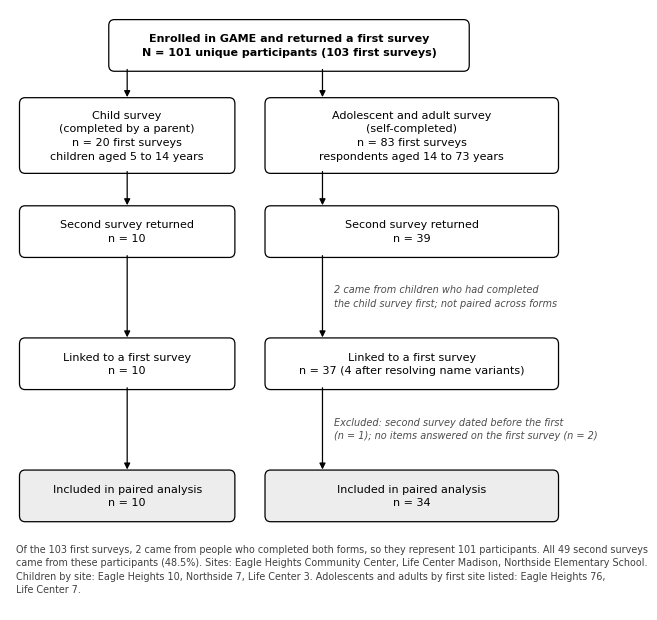

In [15]:
child_range = summary["age_range"]["child_first"]
adult_range = summary["age_range"]["adult_first"]
n_variants = int((adult_second["link_method"] == "name variant").sum())
n_cross = int(adult_second["first_survey_on_child_form"].sum())
n_linked_child = int(child_second["linked_same_form"].sum())
n_linked_adult = int(adult_second["linked_same_form"].sum())
child_sites = child_first["site"].map(first_site).value_counts()
adult_sites = adult_first["site"].map(first_site).value_counts()

fig, ax = plt.subplots(figsize=(7.2, 7.8))
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis("off")


def box(x, y, w, h, text, shaded=False, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.3,rounding_size=1",
                                linewidth=0.9, edgecolor="black",
                                facecolor="#EDEDED" if shaded else "white"))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=8,
            linespacing=1.45, fontweight="bold" if bold else "normal")


def arrow(x, top, bottom):
    ax.annotate("", xy=(x, bottom), xytext=(x, top),
                arrowprops=dict(arrowstyle="-|>", lw=0.9, color="black", shrinkA=0, shrinkB=0))


def side_note(x, y, text):
    ax.text(x, y, text, ha="left", va="center", fontsize=7, color="0.3", style="italic", linespacing=1.4)


LEFT, LEFT_W, RIGHT, RIGHT_W = 2, 38, 46, 52
LEFT_MID, RIGHT_ARROW = LEFT + LEFT_W / 2, 56

box(18, 90, 64, 8, f"Enrolled in GAME and returned a first survey\n"
    f"N = {n_unique} unique participants ({len(child_first) + len(adult_first)} first surveys)", bold=True)
arrow(LEFT_MID, 90, 85.4)
arrow(RIGHT_ARROW, 90, 85.4)

box(LEFT, 73, LEFT_W, 12, f"Child survey\n(completed by a parent)\nn = {len(child_first)} first surveys\n"
    f"children aged {child_range[0]} to {child_range[1]} years")
box(RIGHT, 73, RIGHT_W, 12, f"Adolescent and adult survey\n(self-completed)\nn = {len(adult_first)} first surveys\n"
    f"respondents aged {adult_range[0]} to {adult_range[1]} years")
arrow(LEFT_MID, 73, 67.4)
arrow(RIGHT_ARROW, 73, 67.4)

box(LEFT, 59, LEFT_W, 8, f"Second survey returned\nn = {len(child_second)}")
box(RIGHT, 59, RIGHT_W, 8, f"Second survey returned\nn = {len(adult_second)}")
arrow(LEFT_MID, 59, 45.4)
arrow(RIGHT_ARROW, 59, 45.4)
side_note(RIGHT_ARROW + 2, 52.2, f"{n_cross} came from children who had completed\n"
          "the child survey first; not paired across forms")

box(LEFT, 37, LEFT_W, 8, f"Linked to a first survey\nn = {n_linked_child}")
box(RIGHT, 37, RIGHT_W, 8, f"Linked to a first survey\nn = {n_linked_adult} ({n_variants} after resolving name variants)")
arrow(LEFT_MID, 37, 23.4)
arrow(RIGHT_ARROW, 37, 23.4)
side_note(RIGHT_ARROW + 2, 30.2, f"Excluded: second survey dated before the first\n"
          f"(n = {n_before_first}); no items answered on the first survey (n = {n_no_answers})")

box(LEFT, 15, LEFT_W, 8, f"Included in paired analysis\nn = {n_child_pairs}", shaded=True)
box(RIGHT, 15, RIGHT_W, 8, f"Included in paired analysis\nn = {n_adult_pairs}", shaded=True)

footer = (
    f"Of the {len(child_first) + len(adult_first)} first surveys, {summary['completed_both_first_surveys']} came "
    f"from people who completed both forms, so they represent {n_unique} participants. "
    f"All {n_returned} second surveys came from these participants ({n_returned / n_unique * 100:.1f}%). "
    "Sites: Eagle Heights Community Center, Life Center Madison, Northside Elementary School. "
    f"Children by site: Eagle Heights {child_sites['Eagle Heights Community Center']}, "
    f"Northside {child_sites['Northside Elementary School']}, Life Center {child_sites['Life Center Madison']}. "
    f"Adolescents and adults by first site listed: Eagle Heights {adult_sites['Eagle Heights Community Center']}, "
    f"Life Center {adult_sites['Life Center Madison']}."
)
ax.text(1, 11, textwrap.fill(footer, 128), ha="left", va="top", fontsize=6.9, color="0.25", linespacing=1.45)

fig.savefig(FIGURES / "figure1_participant_flow.png", dpi=400, bbox_inches="tight", facecolor="white")
plt.show()

## Figures 2 and 3: perceived impact

Open markers are the first survey and filled markers the second, so the figures still read in greyscale. Counts sit beside each marker and the item denominator is on the right.

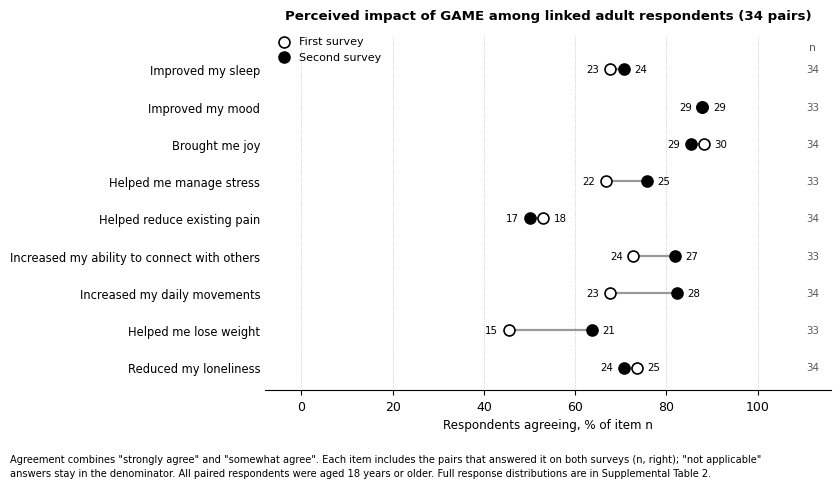

In [16]:
def impact_figure(table, title, note, filename):
    table = table.iloc[::-1]
    y = np.arange(len(table))
    first = table["agree_first"] / table["n"] * 100
    second = table["agree_second"] / table["n"] * 100

    fig, ax = plt.subplots(figsize=(7.3, 4.6))
    for yi, a, b in zip(y, first, second):
        ax.plot([a, b], [yi, yi], color="0.6", lw=1.6, zorder=1, solid_capstyle="round")
    ax.scatter(first, y, s=62, facecolor="white", edgecolor="black", linewidth=1.2, zorder=3,
               label="First survey")
    ax.scatter(second, y, s=62, facecolor="black", edgecolor="black", linewidth=1.2, zorder=3,
               label="Second survey")

    # counts go on the outside of each pair so they never sit on a marker
    for yi, a, b, ca, cb in zip(y, first, second, table["agree_first"], table["agree_second"]):
        (low, low_count), (high, high_count) = sorted([(a, ca), (b, cb)], key=lambda t: t[0])
        ax.text(low - 2.3, yi, str(low_count), ha="right", va="center", fontsize=7.4)
        ax.text(high + 2.3, yi, str(high_count), ha="left", va="center", fontsize=7.4)
    for yi, n in zip(y, table["n"]):
        ax.text(112, yi, str(n), ha="center", va="center", fontsize=7.4, color="0.35")
    ax.set_ylim(-0.6, len(y) - 0.1)
    ax.text(112, len(y) - 0.55, "n", ha="center", va="bottom", fontsize=7.8, color="0.35")

    ax.set_yticks(y)
    ax.set_yticklabels(table.index, fontsize=8.3)
    ax.set_xlim(-8, 116)
    ax.set_xticks(range(0, 101, 20))
    ax.set_xlabel("Respondents agreeing, % of item n", fontsize=8.6)
    ax.set_title(title, fontsize=9.6, fontweight="bold", pad=12)
    ax.grid(axis="x", linestyle=":", linewidth=0.6, color="0.75", zorder=0)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.legend(loc="upper left", bbox_to_anchor=(0.0, 1.02), frameon=False, fontsize=8,
              handletextpad=0.4, borderpad=0.2)
    # line the footnote up with the left edge of the item labels
    fig.canvas.draw()
    left = ax.get_tightbbox(fig.canvas.get_renderer()).x0 / fig.bbox.width
    fig.text(left, -0.03, textwrap.fill(note, 150), fontsize=7.1, ha="left", va="top", linespacing=1.45)
    fig.savefig(FIGURES / filename, dpi=400, bbox_inches="tight", facecolor="white")
    plt.show()


impact_figure(
    adults,
    f"Perceived impact of GAME among linked adult respondents ({n_adult_pairs} pairs)",
    'Agreement combines "strongly agree" and "somewhat agree". Each item includes the pairs that answered it on '
    'both surveys (n, right); "not applicable" answers stay in the denominator. All paired respondents were aged '
    '18 years or older. Full response distributions are in Supplemental Table 2.',
    "figure2_linked_adults.png",
)

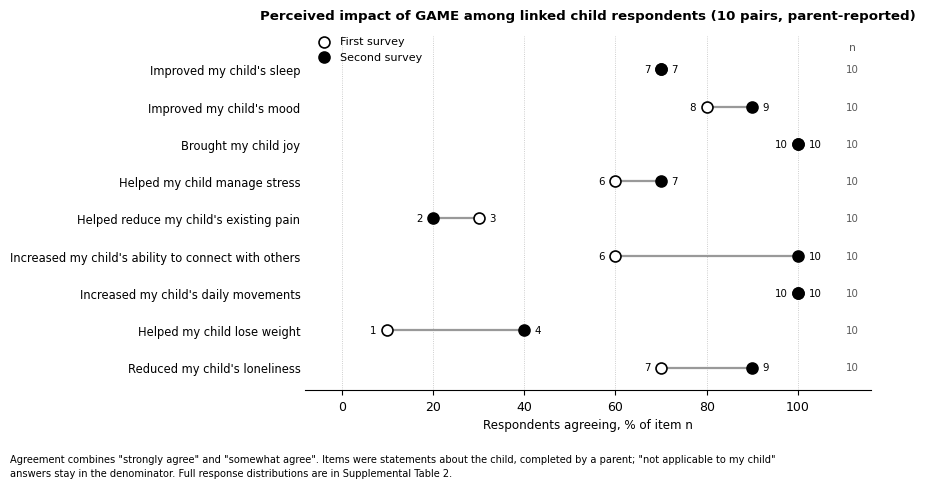

In [17]:
impact_figure(
    children,
    f"Perceived impact of GAME among linked child respondents ({n_child_pairs} pairs, parent-reported)",
    'Agreement combines "strongly agree" and "somewhat agree". Items were statements about the child, completed by '
    'a parent; "not applicable to my child" answers stay in the denominator. Full response distributions are in '
    'Supplemental Table 2.',
    "figure3_linked_children.png",
)

## Saving the results

Everything here is aggregated. No row in the workbook describes a single person.

In [18]:
def with_percent(table):
    return table[["n", "agree_first", "agree_first_pct", "agree_second", "agree_second_pct",
                  "change", "disagree_first", "disagree_second"]]


with pd.ExcelWriter(TABLES / "game_results.xlsx") as writer:
    table1.to_excel(writer, sheet_name="Table1_characteristics")
    supp1.to_excel(writer, sheet_name="SuppTable1_advisory_board")
    supp2.to_excel(writer, sheet_name="SuppTable2_distributions")
    with_percent(adults).to_excel(writer, sheet_name="Figure2_linked_adults")
    with_percent(children).to_excel(writer, sheet_name="Figure3_linked_children")
    sensitivity_board.to_excel(writer, sheet_name="Sensitivity_no_board")
    sensitivity_flip.to_excel(writer, sheet_name="Sensitivity_no_flips")
    intervals.to_excel(writer, sheet_name="Survey_intervals")
    flow.rename("count").to_frame().to_excel(writer, sheet_name="Participant_flow")
    qualitative.to_excel(writer, sheet_name="Qualitative_sample", index=False)

print("saved", (TABLES / "game_results.xlsx").relative_to(ROOT))
for path in sorted(FIGURES.glob("*.png")):
    print("saved", path.relative_to(ROOT))

saved results/tables/game_results.xlsx
saved results/figures/figure1_participant_flow.png
saved results/figures/figure2_linked_adults.png
saved results/figures/figure3_linked_children.png
